<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-13/lab-075-classical-shadows.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 075. Classical shadows

Full tomography of $N$ qubits needs $3^N$ measurement settings and returns $4^N-1$ numbers, so it is limited to a few qubits. Many questions about a quantum device need much less, for example the energy of the prepared state, the correlation between two spins or the magnetisation of each site. Classical shadows answer such questions from one set of measurements without reconstructing the state [1,2], and they belong to a wider family of protocols with randomised measurements [3]. Every run of the device measures each qubit in a basis drawn at random and records the basis and the outcome. From these records, called snapshots, one formula predicts the expectation value of any Pauli string, and the number of runs needed for a string acting on $k$ qubits grows as $3^k$, independently of the total number of qubits.

The running example is the ground state of the transverse-field Ising chain of eight qubits at its critical point. We are given a device that prepares this state on demand, single-qubit gates that rotate each qubit into the $X$, $Y$ or $Z$ basis before a measurement in the computational basis, and a budget of $M$ runs, each of which yields one bit string. We derive the snapshot formula on one qubit, check that it is unbiased and that a string of weight $k$ has variance $3^k$, and then estimate the energy and all spin correlations of the chain from one data set with error bars. Finally we follow the error as a function of $M$ and of the number of qubits. The lab succeeds if the estimates agree with the exact values within their error bars and the error bars follow the predicted variance.

Section 2 describes the measurement protocol and derives the snapshot on one qubit, and Section 3 checks it numerically. Section 4 introduces the Ising chain and a sampler of snapshots. Section 5 derives the estimator of a Pauli string and its variance, and Section 6 introduces the median of means. Section 7 estimates the energy and the correlations, Section 8 measures the convergence with $M$ and Section 9 the dependence on $N$. Sections 1 to 9 form the core route, and Section 10, for work at home, compares shadows with tomography at an equal number of runs.

Quantities called exact come from the state vector, which the simulation knows and the experimenter does not. Estimates come from simulated measurement records with fixed random seeds, in the form a device returns them.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that identities hold to about $10^{-12}$. SciPy computes the exact ground state, JAX draws the random bases and outcomes on the CPU, NumPy evaluates the estimators and Matplotlib draws the figures. The cells run in order.

Besides `jax.jit` and the random keys of the earlier labs, the code uses two further JAX tools. The option `static_argnums` of `jax.jit` declares an argument, here the number of runs, to be an ordinary Python number that fixes the shapes of the arrays, and JAX compiles the function once for every value of it. The sampler `jax.random.categorical` receives a table of log-probabilities and draws one outcome index for every entry of the requested shape.

On a laptop CPU the core route, Sections 1 to 9, takes about half a minute, most of it in the pool of snapshots of Section 4 and the size scan of Section 9. The optional cell at the end of Section 6 takes about 1 s. Section 10, for work at home, takes about 10 s. The last code cell, after Section 10, prints the numbers and the runtime, and it also runs directly after the core route.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small calculations; the CPU avoids GPU memory allocation
import json, time, itertools
from functools import partial
from pathlib import Path
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# course palette: tomography (linear inversion) grey, exact black; other series navy, purple, teal
COL = dict(tomo="#9AA0A6", exact="black", grey="#5A6270", rand="#9AA0A6", navy="#002B5C", purple="#6A3D9A", teal="#1B9E77")
# the helpers from here to `sci` save figures and numbers for the lecture notes and can be skipped on a first reading
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}
def panels(name, draws, label_xy=None, width_ratios=None):
    # notes: all panels side by side, 7.0 x 2.9 in, 11 pt; slides: every panel alone as name_a, name_b, ... at 4.6 x 3.1 in, 12-13 pt
    n = len(draws)
    label_xy = label_xy or [(0.03, 0.96, "top")] * n
    fig, axes = plt.subplots(1, n, figsize=(7.0, 2.9), gridspec_kw={"width_ratios": width_ratios} if width_ratios else None)
    for i, (ax, draw) in enumerate(zip(axes, draws)):
        draw(ax)
        ax.text(label_xy[i][0], label_xy[i][1], f"({'abc'[i]})", transform=ax.transAxes, va=label_xy[i][2])
    fig.tight_layout(); save(fig, name); plt.show()
    with plt.rc_context(SLIDE_RC):
        for i, draw in enumerate(draws):
            f1, a1 = plt.subplots(figsize=(4.6, 3.1)); draw(a1); f1.tight_layout(); save(f1, f"{name}_{'abc'[i]}"); plt.close(f1)
def single(name, draw):
    fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw(ax); fig.tight_layout(); save(fig, name); plt.show()
started = time.perf_counter()
NUMBERS = {}
def sci(x, digits=1):
    # LaTeX form of a number in scientific notation for the macro file, e.g. 1.1\times10^{5} (used in math mode)
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
key = jax.random.PRNGKey(75)
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Random measurements and snapshots

In every run of the device each qubit $j$ is measured in a basis $X$, $Y$ or $Z$ drawn at random with equal probability. We write $g_j\in\{X,Y,Z\}$ for the basis drawn for qubit $j$. As in tomography, a basis $g$ is selected by a rotation $\hat u_g$ applied before the measurement in the computational basis, with $\hat u_X=\hat H$, $\hat u_Y=\hat H\hat S^\dagger$ (first $\hat S^\dagger$, then the Hadamard gate) and $\hat u_Z=\hat I$, and bit $b_j=0$ signals the eigenvalue $+1$ of the measured Pauli operator. One run gives one bit string, and the record of run $m$, the list of bases and bits drawn in the sketch, is all that is stored.

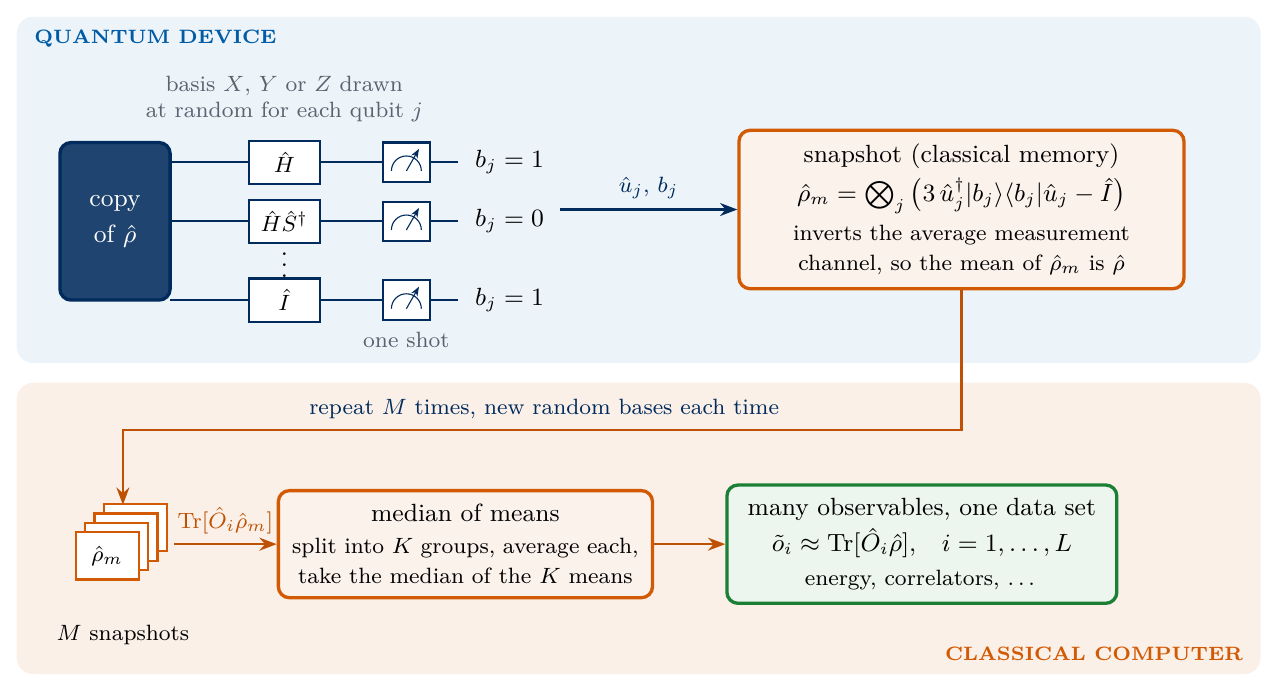

*Classical shadows. Every run measures each qubit in a random basis and records the bases and the bits. Each record defines a snapshot $\hat\rho_m$ whose mean is the state, and many observables are estimated from the same records with the median of means.*

To see how a record can represent the state, we take one qubit in the state $\hat\rho$ and average the post-measurement state $\hat u_g^\dagger|b\rangle\langle b|\hat u_g$ over the random basis and the outcome. Outcome $b$ of basis $P$ has the projector $\hat\pi_{P,b}=\hat u_P^\dagger|b\rangle\langle b|\hat u_P=[\hat I+(-1)^b\hat P]/2$ and the probability $\mathrm{Tr}(\hat\rho\,\hat\pi_{P,b})$. With $\hat\rho=\tfrac12(\hat I+\sum_Pr_P\hat P)$ and $r_P=\langle\hat P\rangle$, the average is
$$\mathcal M(\hat\rho)=\frac13\sum_{P=X,Y,Z}\sum_{b=0,1}\mathrm{Tr}\big(\hat\rho\,\hat\pi_{P,b}\big)\,\hat\pi_{P,b}=\frac13\sum_P\frac{\hat I+r_P\hat P}{2}=\frac{\hat\rho+\hat I}{3} . \tag{1}$$
The middle step uses $\sum_b\frac{1+(-1)^br_P}{2}\,\frac{\hat I+(-1)^b\hat P}{2}=\frac{\hat I+r_P\hat P}{2}$, and the last one uses $\sum_Pr_P\hat P=2\hat\rho-\hat I$. The averaged post-measurement state is the true state mixed with the identity, and this map $\mathcal M$, the measurement channel, can be inverted. Solving equation (1) for $\hat\rho$ gives
$$\mathcal M^{-1}(\hat A)=3\hat A-\mathrm{Tr}(\hat A)\,\hat I . \tag{2}$$
Applying the inverse to a single record defines the snapshot, and for $N$ qubits with independent random bases the channel factorises, so that
$$\hat\rho_m=\bigotimes_{j=0}^{N-1}\Big(3\,\hat u_{g_j}^\dagger|b_j\rangle\langle b_j|\hat u_{g_j}-\hat I\Big),\qquad \mathbb E[\hat\rho_m]=\hat\rho . \tag{3}$$
A snapshot is no density matrix, since each factor has the eigenvalues $2$ and $-1$, but its mean over the random bases and outcomes is the state. The snapshot is a product of $N$ matrices of size $2\times2$ and is stored as the $N$ bases and $N$ bits of the record, never as a $2^N\times2^N$ matrix. On the Bloch ball of one qubit the channel shrinks the Bloch vector by a factor three and the inverse stretches it back.

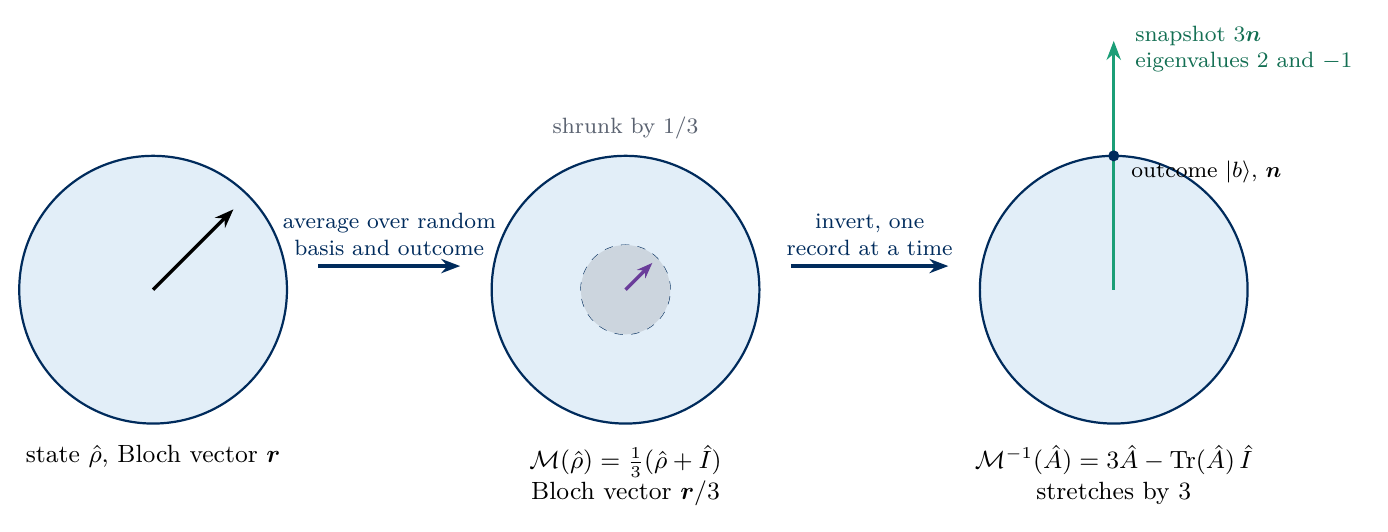

*The measurement channel and its inverse on one qubit. Averaging over random bases and outcomes shrinks the Bloch vector $\boldsymbol r$ to $\boldsymbol r/3$. Applied to a single record whose outcome has the Bloch vector $\boldsymbol n$, the inverse gives the snapshot with Bloch vector $3\boldsymbol n$, outside the ball, with eigenvalues $2$ and $-1$.*

## 3. One qubit

We check equations (1) and (2) for a one-qubit mixed state with Bloch vector $(0.3,-0.5,0.6)$. The average of equation (1) is evaluated exactly, by summing over the three bases and two outcomes with their Born probabilities. We then draw $M$ random records, average the snapshots of equation (3) and compare the mean with the state. The snapshots are independent and have the mean $\hat\rho$, so the cross terms of different snapshots average to zero and $\mathbb E\,\|\bar\rho_M-\hat\rho\|_{\mathrm{HS}}^2=(\mathbb E\,\mathrm{Tr}\,\hat\rho_m^2-\mathrm{Tr}\,\hat\rho^2)/M$. Every one-qubit snapshot has the eigenvalues $2$ and $-1$ and therefore $\mathrm{Tr}\,\hat\rho_m^2=5$, which gives
$$\mathbb E\,\big\|\bar\rho_M-\hat\rho\big\|_{\mathrm{HS}}^2=\frac{5-\mathrm{Tr}\,\hat\rho^2}{M},\qquad \bar\rho_M=\frac1M\sum_{m=1}^M\hat\rho_m , \tag{4}$$
where $\bar\rho_M$ is the mean of the $M$ snapshots. As a control, the average of the post-measurement states without the inverse channel must converge to $(\hat\rho+\hat I)/3$ and miss the state.

M =     10: rms distance of the snapshot mean 0.6438, equation (4) 0.6442;  without the inverse channel 0.420
M =    100: rms distance of the snapshot mean 0.1936, equation (4) 0.2037;  without the inverse channel 0.395
M =   1000: rms distance of the snapshot mean 0.0644, equation (4) 0.0644;  without the inverse channel 0.397
M =  10000: rms distance of the snapshot mean 0.0224, equation (4) 0.0204;  without the inverse channel 0.394
M = 100000: rms distance of the snapshot mean 0.0074, equation (4) 0.0064;  without the inverse channel 0.395


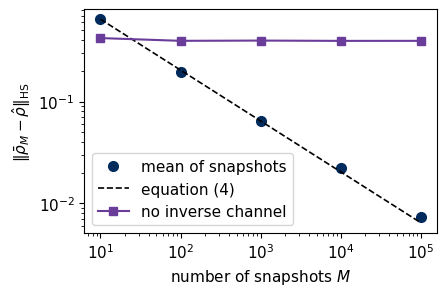

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
HAD = (X + Z) / np.sqrt(2)                           # Hadamard gate
SDG = np.diag([1, -1j])                              # S^dagger
BASES = "XYZ"                                        # basis code 0 = X, 1 = Y, 2 = Z
ROT = np.stack([HAD, HAD @ SDG, I2])                 # u for each basis code
PAULI3 = np.stack([X, Y, Z])
for c in range(3):
    assert np.allclose(ROT[c].conj().T @ Z @ ROT[c], PAULI3[c])   # measuring Z after u measures the Pauli operator
POST = np.einsum("cbi,cbj->cbij", ROT.conj(), ROT)   # u^dagger |b><b| u for every basis c and bit b, shape (3, 2, 2, 2)
SNAP1 = 3 * POST - I2                                # one-qubit snapshots of equation (3)
for c in range(3):
    for b in range(2):
        assert np.allclose(POST[c, b], (I2 + (-1) ** b * PAULI3[c]) / 2)
        assert np.allclose(np.linalg.eigvalsh(SNAP1[c, b]), [-1, 2])

r1 = np.array([0.3, -0.5, 0.6])
rho1 = 0.5 * (I2 + np.einsum("c,cij->ij", r1, PAULI3))
prob1 = np.real(np.einsum("cbij,ji->cb", POST, rho1))            # Born probabilities, shape (3, 2)
channel = np.einsum("cb,cbij->ij", prob1 / 3, POST)              # equation (1), exact average
assert np.allclose(channel, (rho1 + I2) / 3)
assert np.allclose(3 * channel - np.trace(channel) * I2, rho1)   # equation (2)

M_GRID1, R1 = np.array([10, 100, 1000, 10000, 100000]), 40
err_snap, err_post = np.zeros((len(M_GRID1), R1)), np.zeros((len(M_GRID1), R1))
key, k1, k2 = jax.random.split(key, 3)
c_rec = jax.random.randint(k1, (R1, M_GRID1.max()), 0, 3)                       # random bases of R1 data sets
b_rec = jax.random.bernoulli(k2, jnp.asarray(prob1[:, 1])[c_rec]).astype(int)  # bit 1 with its Born probability
codes = np.asarray(2 * c_rec + b_rec)                                           # record (c, b) stored as 2c + b
for i, M in enumerate(M_GRID1):
    freq = (codes[:, :M, None] == np.arange(6)).mean(axis=1)                    # fraction of the first M records with each (c, b)
    snap_mean = np.einsum("rk,kij->rij", freq, SNAP1.reshape(6, 2, 2))
    post_mean = np.einsum("rk,kij->rij", freq, POST.reshape(6, 2, 2))
    err_snap[i] = np.sqrt(np.sum(np.abs(snap_mean - rho1) ** 2, axis=(1, 2)))
    err_post[i] = np.sqrt(np.sum(np.abs(post_mean - rho1) ** 2, axis=(1, 2)))
purity1 = np.real(np.trace(rho1 @ rho1))
pred1 = np.sqrt((5 - purity1) / M_GRID1)
rms1 = np.sqrt((err_snap ** 2).mean(axis=1))
limit_post = np.sqrt(np.sum(np.abs((rho1 + I2) / 3 - rho1) ** 2))
assert np.all(np.abs(rms1 / pred1 - 1) < 0.25)
assert abs(err_post[-1].mean() - limit_post) < 0.01
for M, e, p, w in zip(M_GRID1, rms1, pred1, err_post.mean(axis=1)):
    print(f"M = {M:6d}: rms distance of the snapshot mean {e:.4f}, equation (4) {p:.4f};  without the inverse channel {w:.3f}")
NUMBERS.update(LimitNoInverse=f"{limit_post:.2f}")

def one_qubit_panel(ax):
    ax.loglog(M_GRID1, rms1, "o", color=COL["navy"], ms=7, label="mean of snapshots")
    ax.loglog(M_GRID1, pred1, color=COL["exact"], lw=1.2, ls="--", label="equation (4)")
    ax.loglog(M_GRID1, err_post.mean(axis=1), "s-", color=COL["purple"], lw=1.5, label="no inverse channel")
    ax.set_xlabel(r"number of snapshots $M$"); ax.set_ylabel(r"$\|\bar\rho_M-\hat\rho\|_{\mathrm{HS}}$")
    ax.legend(loc="lower left")
single("fig_lab075_one_qubit", one_qubit_panel)

The exact average reproduces equation (1), and its inverse returns the state. The figure shows the root-mean-square distance between the mean of $M$ snapshots and the true state, from 40 independent data sets, of which the first $M$ records are used. It decreases as $M^{-1/2}$ along equation (4), so the snapshots are unbiased. The points lie within 16 % of the line, a scatter expected for a root mean square taken over only 40 data sets. Without the inverse channel the distance stops at the distance between $(\hat\rho+\hat I)/3$ and $\hat\rho$ for every $M$, because the averaged post-measurement state is a mixture of the state with noise.

## 4. The Ising chain and the snapshot sampler

The state whose properties we predict is the ground state of the transverse-field Ising chain with open ends [4],
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i , \tag{5}$$
with $J=h=1$, the critical point of the infinite chain, and $N=8$. The coupling $J$ favours aligned neighbours along $z$, the field $h$ favours every spin along $x$, and at $h=J$ the competition produces correlations that decay slowly with distance.

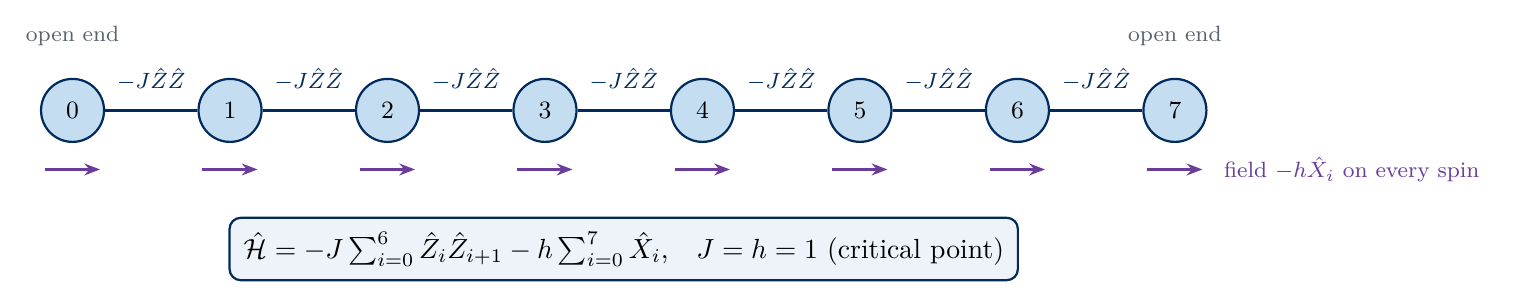

*The open Ising chain of eight spins with the coupling $-J\hat Z_i\hat Z_{i+1}$ between neighbours and the field $-h\hat X_i$ on every spin, at $J=h=1$.*

We obtain the exact ground state with the sparse Lanczos-type solver `eigsh` of SciPy [5] for comparison. The device then prepares this state $M$ times. The sampler draws the bases of all runs at once, applies to every run its own rotations to the $2^N$ amplitudes of the state, with qubit 0 as the most significant bit, and draws one bit string per run from the rotated amplitudes. All operations are vectorised over runs in JAX [6]. We record a pool of $100\,000$ runs once and use parts of it in the following sections.

In [3]:
N, J, h = 8, 1.0, 1.0
SPARSE = {"I": sp.identity(2, format="csr", dtype=complex), "X": sp.csr_matrix(X), "Y": sp.csr_matrix(Y), "Z": sp.csr_matrix(Z)}

def pauli_sparse(n, factors):
    # Kronecker product over qubits 0..n-1 (qubit 0 leftmost); factors = {qubit: "X", "Y" or "Z"}
    out = sp.identity(1, format="csr", dtype=complex)
    for q in range(n):
        out = sp.kron(out, SPARSE[factors.get(q, "I")], format="csr")
    return out

def tfim_ground_state(n, J=1.0, h=1.0):
    H = sp.csr_matrix((2 ** n, 2 ** n), dtype=complex)
    for i in range(n - 1):
        H = H - J * pauli_sparse(n, {i: "Z", i + 1: "Z"})
    for i in range(n):
        H = H - h * pauli_sparse(n, {i: "X"})                    # equation (5)
    w, v = eigsh(H, k=1, which="SA")
    return float(w[0]), v[:, 0], H

def exact_expectation(psi, factors):
    return float(np.real(np.vdot(psi, pauli_sparse(int(np.log2(psi.size)), factors) @ psi)))

E0, psi0, H_sp = tfim_ground_state(N, J, h)
assert abs(np.vdot(psi0, H_sp @ psi0).real - E0) < 1e-10 and abs(np.linalg.norm(psi0) - 1) < 1e-12
ROT_J = jnp.asarray(ROT)

@partial(jax.jit, static_argnums=2)
def snapshots(key, psi, M):
    # M runs: random basis codes (M, n) and one measured bit string (M, n) per run
    n = int(np.log2(psi.size))
    k1, k2 = jax.random.split(key)
    bases = jax.random.randint(k1, (M, n), 0, 3)
    phi = jnp.broadcast_to(jnp.asarray(psi, dtype=complex), (M, psi.size))
    for q in range(n):
        U = ROT_J[bases[:, q]]                                   # the rotation of qubit q in every run, (M, 2, 2)
        phi = phi.reshape(M, 2 ** q, 2, 2 ** (n - q - 1))        # axes: run, qubits before q, qubit q, qubits after q
        phi = jnp.einsum("mab,mlbr->mlar", U, phi).reshape(M, -1)   # apply the 2 x 2 rotation to the axis of qubit q
    cdf = jnp.cumsum(jnp.abs(phi) ** 2, axis=1)                  # Born probabilities of the rotated state
    u = jax.random.uniform(k2, (M, 1))                           # one uniform number per run; the index is the first one whose
                                                                 # cumulative probability exceeds it (inverse-CDF sampling)
    idx = jnp.minimum(jnp.sum(cdf < u * cdf[:, -1:], axis=1), psi.size - 1)
    # index to bits, with qubit 0 as the most significant bit
    return bases.astype(jnp.int8), ((idx[:, None] >> jnp.arange(n - 1, -1, -1)) & 1).astype(jnp.int8)

def collect(key, psi, M, chunk=10000):
    parts = []
    for start in range(0, M, chunk):
        key, k = jax.random.split(key)
        parts.append([np.asarray(a) for a in snapshots(k, psi, min(chunk, M - start))])
    return np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts])

M_POOL = 100000
key, k = jax.random.split(key)
t0 = time.perf_counter()
POOL_BASES, POOL_BITS = collect(k, psi0, M_POOL)
print(f"N = {N}, J = h = 1: exact E_0 = {E0:.6f}")
print(f"{M_POOL} snapshots recorded in {time.perf_counter() - t0:.1f} s; first record: bases",
      "".join(BASES[c] for c in POOL_BASES[0]), " bits", "".join(map(str, POOL_BITS[0])))
NUMBERS.update(N=f"{N}", EZero=f"{E0:.4f}", MPool=f"{M_POOL:,}".replace(",", "\\,"))

N = 8, J = h = 1: exact E_0 = -9.837951
100000 snapshots recorded in 3.2 s; first record: bases YZXXYYXX  bits 11001100


## 5. Pauli strings from snapshots

A Pauli string $\hat P$ of weight $k$ has non-identity letters $P_j$ on the $k$ qubits of its support. Its expectation value in the snapshot (3) follows from one-qubit traces, $\mathrm{Tr}[\hat I(3\hat\pi-\hat I)]=1$ on qubits outside the support and $\mathrm{Tr}[\hat P_j(3\hat\pi_{g_j,b_j}-\hat I)]=3(-1)^{b_j}$ if the measured basis $g_j$ equals $P_j$, and zero otherwise. The value of run $m$ is therefore
$$o_m(\hat P)=\mathrm{Tr}\big[\hat P\hat\rho_m\big]=\prod_{j\in\mathrm{supp}\hat P}3\,\delta_{g_j,P_j}\,(-1)^{b_j} , \tag{6}$$
and the estimate from $M$ runs is the mean $\tilde o(\hat P)=\frac1M\sum_mo_m(\hat P)$. The value is $\pm3^k$ when the random bases agree with the string on all $k$ qubits, which happens with probability $3^{-k}$, and zero otherwise. Its second moment and variance are thus
$$\mathbb E[o_m^2]=3^{-k}\,9^k=3^k,\qquad \mathrm{Var}(o_m)=3^k-\langle\hat P\rangle^2,\qquad \sigma_{\tilde o}=\sqrt{\frac{3^k-\langle\hat P\rangle^2}{M}} , \tag{7}$$
independent of $N$.

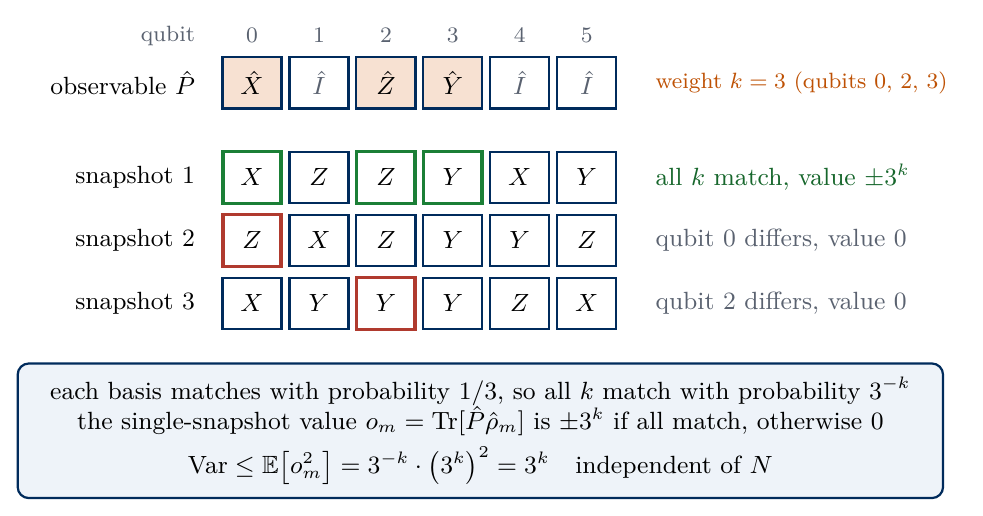

*A string of weight $k$ is seen only by the runs whose random bases agree with it on all $k$ qubits of its support. Such a run contributes $\pm3^k$, all others contribute zero, and the second moment $3^k$ does not depend on the number of qubits.*

We check equations (6) and (7) on the strings $\hat Z_0\hat Z_1\cdots\hat Z_{k-1}$ for $k=1,\dots,8$ with the whole pool. The ground state is an eigenstate of the parity $\hat\Pi=\prod_i\hat X_i$, which flips every $\hat Z_i$, so strings of odd $k$ have expectation value zero. As a control, the estimate without the factor 3 per qubit, which omits the inverse channel, must disagree with the exact values.

k = 1: E[o^2] =      3.0 (3^k =     3),  estimate +0.0042 +- 0.0055, exact -0.0000
k = 2: E[o^2] =      9.0 (3^k =     9),  estimate +0.5189 +- 0.0094, exact +0.5056
k = 3: E[o^2] =     26.9 (3^k =    27),  estimate +0.0067 +- 0.0164, exact +0.0000
k = 4: E[o^2] =     81.4 (3^k =    81),  estimate +0.3321 +- 0.0285, exact +0.3058
k = 5: E[o^2] =    238.6 (3^k =   243),  estimate -0.0778 +- 0.0488, exact +0.0000
k = 6: E[o^2] =    706.8 (3^k =   729),  estimate +0.2551 +- 0.0841, exact +0.1881
k = 7: E[o^2] =   1913.2 (3^k =  2187),  estimate +0.0437 +- 0.1383, exact +0.0000
k = 8: E[o^2] =   6457.0 (3^k =  6561),  estimate +0.4593 +- 0.2541, exact +0.1013
control without the factor 3 per qubit, deviation in standard errors: [ -430.  -857. -1628. -2613.]
runs with matching bases for k = 8: 15


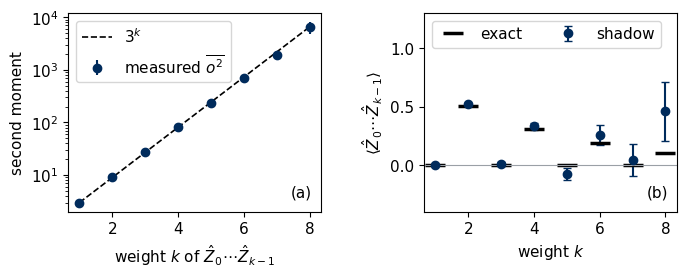

In [4]:
def snapshot_values(bases, bits, string):
    # equation (6); string = {qubit: basis code}, the support of the Pauli string
    v = np.ones(bases.shape[0])
    for q, c in string.items():
        v = v * 3.0 * (bases[:, q] == c) * (1 - 2.0 * bits[:, q])
    return v

ZCODE, XCODE = 2, 0
k_list = np.arange(1, N + 1)
mom2, mom2_se, est, est_se, exact_z = [], [], [], [], []
for kk in k_list:
    string = {q: ZCODE for q in range(kk)}
    v = snapshot_values(POOL_BASES, POOL_BITS, string)
    p_match = np.mean(v != 0)
    mom2.append(np.mean(v ** 2)); mom2_se.append(9.0 ** kk * np.sqrt(3.0 ** -kk * (1 - 3.0 ** -kk) / M_POOL))
    est.append(v.mean()); est_se.append(v.std(ddof=1) / np.sqrt(M_POOL)); n_match = int(np.sum(v != 0))
    exact_z.append(exact_expectation(psi0, {q: "Z" for q in range(kk)}))
mom2, mom2_se, est, est_se, exact_z = map(np.array, (mom2, mom2_se, est, est_se, exact_z))
z_mom2 = (mom2 - 3.0 ** k_list) / mom2_se
z_est = (est - exact_z) / est_se
z_wrong = (est / 3.0 ** k_list - exact_z) / (est_se / 3.0 ** k_list)
assert np.all(np.abs(z_mom2) < 4) and np.all(np.abs(z_est) < 4)
assert np.max(np.abs(z_wrong[exact_z != 0])) > 10                  # the control without the factor 3 must fail
for kk, m2, e, s, x in zip(k_list, mom2, est, est_se, exact_z):
    print(f"k = {kk}: E[o^2] = {m2:8.1f} (3^k = {3 ** kk:5d}),  estimate {e:+.4f} +- {s:.4f}, exact {x:+.4f}")
print("control without the factor 3 per qubit, deviation in standard errors:", np.round(z_wrong[1::2], 0))

def moment_panel(ax):
    ax.errorbar(k_list, mom2, yerr=mom2_se, fmt="o", color=COL["navy"], ms=6, label=r"measured $\overline{o^2}$")
    ax.semilogy(k_list, 3.0 ** k_list, color=COL["exact"], ls="--", lw=1.2, label=r"$3^k$")
    ax.set_yscale("log"); ax.set_xlabel(r"weight $k$ of $\hat Z_0\cdots\hat Z_{k-1}$"); ax.set_ylabel("second moment")
    ax.legend(loc="upper left")
def string_panel(ax):
    ax.errorbar(k_list, est, yerr=est_se, fmt="o", color=COL["navy"], ms=6, capsize=3, label="shadow")
    ax.plot(k_list, exact_z, "_", ms=14, mew=2.5, color=COL["exact"], label="exact")
    ax.axhline(0, color=COL["rand"], lw=0.8)
    ax.set_ylim(-0.4, max(1.3, (est + est_se).max() + 0.45))
    ax.set_xlabel(r"weight $k$"); ax.set_ylabel(r"$\langle\hat Z_0\cdots\hat Z_{k-1}\rangle$"); ax.legend(loc="upper left", ncol=2)
panels("fig_lab075_variance", [moment_panel, string_panel], label_xy=[(0.88, 0.06, "bottom"), (0.88, 0.06, "bottom")])
print(f"runs with matching bases for k = {N}: {n_match}")
NUMBERS.update(MatchWeightEight=f"{n_match}", SigmaWeightEight=f"{est_se[-1]:.2f}", SigmaWeightTwo=f"{est_se[1]:.4f}")

Panel (a) shows the measured second moment of the single-run values against the weight. It follows $3^k$ over more than three decades. Panel (b) shows the estimates of $\langle\hat Z_0\cdots\hat Z_{k-1}\rangle$ from all $100\,000$ runs with their standard errors (7). The estimates agree with the exact values, which vanish for odd $k$, and the error bars grow by a factor $\sqrt3$ per added qubit of the support. For $k=8$ only about 15 runs of the pool have matching bases, and the error bar is larger than the expectation value. Shadows are therefore efficient for strings of low weight and inefficient for strings that act on the whole system.

## 6. Many observables and the median of means

One data set serves all observables at once, so we ask for the number of runs which guarantees that all $L$ estimates lie within $\varepsilon$ of their exact values with probability at least $1-\delta$. The Chebyshev inequality states that a random variable $x$ with mean $\mu$ and variance $\sigma^2$ obeys $\mathrm{Prob}(|x-\mu|\geq\varepsilon)\leq\sigma^2/\varepsilon^2$. A mean of $n$ runs has the variance $\sigma^2/n$, so it misses the exact value by more than $\varepsilon$ with a probability of at most $\sigma^2/(n\varepsilon^2)$, a bound that decreases only as $1/n$. The median of means turns this into an exponential bound [7,8]. The $M$ runs are split into $K$ groups of $n=M/K$ runs, the estimate is formed in every group, and the median of the $K$ group means is the final estimate,
$$\tilde o_{\mathrm{MoM}}=\mathrm{median}\big(\tilde o^{(1)},\dots,\tilde o^{(K)}\big) . \tag{8}$$
With $n=4\sigma^2/\varepsilon^2$ runs per group, the Chebyshev inequality says that each group mean is wrong by more than $\varepsilon$ with a probability of at most $1/4$. When more than half of the group means lie within $\varepsilon$ of the exact value, the median lies within $\varepsilon$ as well, so the median fails only if at least half of the $K$ groups fail. The groups are independent, and the number of failed groups behaves as the number of heads in $K$ tosses of a coin that shows heads with probability $1/4$. The probability of at least $K/2$ heads decreases exponentially with $K$, and Hoeffding's inequality bounds it by $e^{-K/8}$. The probability that at least one of $L$ estimates fails is at most the sum of the $L$ failure probabilities, so it is below $\delta$ when each estimate fails with a probability of at most $\delta/L$. The condition $e^{-K/8}\leq\delta/L$ gives $K=8\ln(L/\delta)$ groups. With the single-run variance $\sigma^2\leq3^k$ of equation (7), the total number of runs $M=Kn$ that estimates every one of $L$ strings of weight at most $k$ to accuracy $\varepsilon$ with probability $1-\delta$ is
$$M=O\Big(\frac{3^k\,\ln(L/\delta)}{\varepsilon^2}\Big) \tag{9}$$
[1]. The number of observables enters only through a logarithm, and the number of qubits does not enter.

The code compares the plain mean with the median of means for all $L=276$ Pauli strings of weight one and two on the chain. It splits the pool into 50 independent data sets of $2000$ runs and, in each data set, computes the largest error over the 276 strings, once with the mean and once with $K=10$ groups of 200 runs. All one- and two-qubit estimates of a data set follow from the matrix $A_{mjc}=3\,\delta_{g_j,c}(-1)^{b_j}$ of single-qubit factors by one contraction over runs.

L = 276 strings, 50 data sets of M = 2000 runs
largest error over all strings: mean 0.205 (worst data set 0.275), median of means 0.238 (worst 0.360)
rms error of a weight-2 estimate: mean 0.0658, median of means 0.0779, equation (7) 0.0669


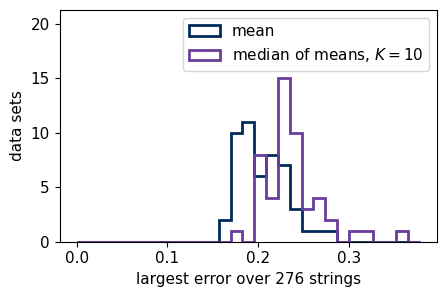

In [5]:
def factor_matrix(bases, bits):
    # A[m, j, c] = 3 delta(g_j, c) (-1)^{b_j}: single-qubit factors of equation (6), basis codes c = 0, 1, 2 for X, Y, Z
    return 3.0 * (bases[..., None] == np.arange(3)) * (1 - 2.0 * bits[..., None])

PAIRS = [(i, j) for i in range(N) for j in range(i + 1, N)]
pair_i, pair_j = np.array(PAIRS).T
exact1 = np.array([[exact_expectation(psi0, {i: BASES[c]}) for c in range(3)] for i in range(N)])                    # (N, 3)
exact2 = np.array([[[exact_expectation(psi0, {i: BASES[a], j: BASES[b]}) for b in range(3)] for a in range(3)] for i, j in PAIRS])  # (28, 3, 3)
L_obs = exact1.size + exact2.size

def estimates(A):
    # all weight-1 and weight-2 estimates from runs A[..., m, j, c]: means over the run axis
    one = A.mean(axis=-3)
    two = np.einsum("...mia,...mib->...iab", A[..., pair_i, :], A[..., pair_j, :]) / A.shape[-3]
    return one, two

M_BLOCK, K_GROUPS = 2000, 10
A_pool = factor_matrix(POOL_BASES, POOL_BITS)
blocks = A_pool.reshape(M_POOL // M_BLOCK, M_BLOCK, N, 3)
one_mean, two_mean = estimates(blocks)
groups = blocks.reshape(M_POOL // M_BLOCK, K_GROUPS, M_BLOCK // K_GROUPS, N, 3)
one_g, two_g = estimates(groups)
one_mom, two_mom = np.median(one_g, axis=1), np.median(two_g, axis=1)
def max_error(one, two):
    return np.maximum(np.abs(one - exact1).max(axis=(-2, -1)), np.abs(two - exact2).max(axis=(-3, -2, -1)))
maxerr_mean, maxerr_mom = max_error(one_mean, two_mean), max_error(one_mom, two_mom)
rms_two_mean = np.sqrt(np.mean((two_mean - exact2) ** 2)); rms_two_mom = np.sqrt(np.mean((two_mom - exact2) ** 2))
assert abs(rms_two_mean / np.sqrt(np.mean(9 - exact2 ** 2) / M_BLOCK) - 1) < 0.1     # equation (7) for weight two
print(f"L = {L_obs} strings, {M_POOL // M_BLOCK} data sets of M = {M_BLOCK} runs")
print(f"largest error over all strings: mean {maxerr_mean.mean():.3f} (worst data set {maxerr_mean.max():.3f}), "
      f"median of means {maxerr_mom.mean():.3f} (worst {maxerr_mom.max():.3f})")
print(f"rms error of a weight-2 estimate: mean {rms_two_mean:.4f}, median of means {rms_two_mom:.4f}, equation (7) {np.sqrt(np.mean(9 - exact2 ** 2) / M_BLOCK):.4f}")
NUMBERS.update(LObs=f"{L_obs}", MaxErrMean=f"{maxerr_mean.mean():.2f}", MaxErrMoM=f"{maxerr_mom.mean():.2f}",
               RmsTwoMean=f"{rms_two_mean:.3f}", RmsTwoMoM=f"{rms_two_mom:.3f}")

def mom_panel(ax):
    bins = np.linspace(0, max(maxerr_mean.max(), maxerr_mom.max()) * 1.05, 30)
    ax.hist(maxerr_mean, bins=bins, histtype="step", lw=2, color=COL["navy"], label="mean")
    ax.hist(maxerr_mom, bins=bins, histtype="step", lw=2, color=COL["purple"], label=f"median of means, $K={K_GROUPS}$")
    ax.set_xlabel(f"largest error over {L_obs} strings"); ax.set_ylabel("data sets"); ax.legend(loc="upper right")
    ax.set_ylim(0, 1.35 * ax.get_ylim()[1])
single("fig_lab075_median_of_means", mom_panel)

The rms error of a weight-two estimate agrees with equation (7). The figure shows, for the 50 data sets, the largest error over all 276 strings. In this experiment the median of means is slightly less accurate than the plain mean. Its largest error is $0.24$ on average against $0.21$ for the mean, and its rms error for a weight-two string is $0.078$ against $0.066$. The single-run values are bounded by $3^k$, so the mean of 2000 runs is already close to Gaussian, while each group of the median of means has only 200 runs and the median of ten group means fluctuates more than the mean of all runs. The bound (9) concerns the probability of rare large errors, and its derivation needs only a finite variance.

The next cell is optional and takes about 1 s. It first repeats the comparison for the weight-six string $\hat Z_0\cdots\hat Z_5$, which only about three of the 2000 runs of a data set match. It then applies both estimators to random numbers with heavy tails in place of single-run values. They are drawn from Student's $t$ distribution with $2.5$ degrees of freedom, which has the mean zero, a finite variance and large values that are far more frequent than for a Gaussian. Each of the $10\,000$ data sets again has 2000 values and $K=10$ groups.

In [6]:
# optional, about 1 s: two further comparisons of the mean and the median of means
t0 = time.perf_counter()
v6 = snapshot_values(POOL_BASES, POOL_BITS, {q: ZCODE for q in range(6)}).reshape(M_POOL // M_BLOCK, M_BLOCK)   # weight-six string
x6 = exact_expectation(psi0, {q: "Z" for q in range(6)})
mean6, mom6 = v6.mean(axis=1), np.median(v6.reshape(-1, K_GROUPS, M_BLOCK // K_GROUPS).mean(axis=2), axis=1)
rms = lambda e: float(np.sqrt(np.mean(e ** 2)))
print(f"weight-six string, exact value {x6:.3f}, {v6.shape[0]} data sets of {M_BLOCK} runs, about {M_BLOCK / 3 ** 6:.1f} matching runs each")
print(f"  mean           : rms error {rms(mean6 - x6):.2f}, largest error {np.abs(mean6 - x6).max():.2f}")
print(f"  median of means: rms error {rms(mom6 - x6):.2f}, largest error {np.abs(mom6 - x6).max():.2f}, equal to zero in {100 * np.mean(mom6 == 0):.0f} % of the data sets")

R_T, DOF_T = 10000, 2.5
t_val = np.random.default_rng(75).standard_t(DOF_T, size=(R_T, M_BLOCK))                # heavy-tailed numbers with mean zero
mean_t, mom_t = t_val.mean(axis=1), np.median(t_val.reshape(R_T, K_GROUPS, M_BLOCK // K_GROUPS).mean(axis=2), axis=1)
sigma_t = np.sqrt(DOF_T / (DOF_T - 2) / M_BLOCK)                                        # standard error of the mean
print(f"Student t values with {DOF_T} degrees of freedom, {R_T} data sets of {M_BLOCK} values, standard error {sigma_t:.3f}")
for name_, e_ in (("mean           ", mean_t), ("median of means", mom_t)):
    print(f"  {name_}: rms error {rms(e_):.3f}, largest error {np.abs(e_).max():.2f}, "
          f"errors above four standard errors in {int(np.sum(np.abs(e_) > 4 * sigma_t))} data sets")
mom_demo = dict(weight6=dict(exact=x6, rms_mean=rms(mean6 - x6), rms_mom=rms(mom6 - x6), max_mean=float(np.abs(mean6 - x6).max()),
                             max_mom=float(np.abs(mom6 - x6).max()), fraction_mom_zero=float(np.mean(mom6 == 0))),
                student_t=dict(dof=DOF_T, data_sets=R_T, values=M_BLOCK, groups=K_GROUPS, standard_error=float(sigma_t), rms_mean=rms(mean_t), rms_mom=rms(mom_t),
                               max_mean=float(np.abs(mean_t).max()), max_mom=float(np.abs(mom_t).max()),
                               above_4se_mean=int(np.sum(np.abs(mean_t) > 4 * sigma_t)), above_4se_mom=int(np.sum(np.abs(mom_t) > 4 * sigma_t))))
print(f"{time.perf_counter() - t0:.1f} s")

weight-six string, exact value 0.188, 50 data sets of 2000 runs, about 2.7 matching runs each
  mean           : rms error 0.65, largest error 1.63
  median of means: rms error 0.30, largest error 1.63, equal to zero in 98 % of the data sets
Student t values with 2.5 degrees of freedom, 10000 data sets of 2000 values, standard error 0.050
  mean           : rms error 0.050, largest error 0.76, errors above four standard errors in 15 data sets
  median of means: rms error 0.052, largest error 0.21, errors above four standard errors in 2 data sets
1.1 s


For the weight-six string the median of means is zero in 98 % of the data sets, because most groups of 200 runs contain no matching run. Its rms error, $0.30$ against $0.65$ for the mean, is small only because the exact value $0.19$ is itself close to zero, and its largest error is the same as that of the mean. For this Pauli string the median therefore brings no real improvement. For the heavy-tailed numbers the two estimators have nearly the same rms error, $0.050$ and $0.052$. The mean, however, misses by more than four standard errors in 15 of the $10\,000$ data sets and the median of means in 2, and the largest error is $0.76$ for the mean and $0.21$ for the median of means. The median thus suppresses rare large errors, which is the property used in the derivation of the bound (9). In the following sections we use the mean with its standard error.

## 7. Energy and correlations from one data set

We use the first $M=20\,000$ runs of the pool as one experiment and estimate from it the energy, the magnetisation $\langle\hat X_i\rangle$ of every site and the correlations $\langle\hat Z_i\hat Z_j\rangle$ of all 28 pairs. By equations (5) and (6) every run gives an energy value
$$e_m=-J\sum_{i=0}^{N-2}o_m(\hat Z_i\hat Z_{i+1})-h\sum_{i=0}^{N-1}o_m(\hat X_i) , \tag{10}$$
and the energy estimate is the mean of $e_m$ with the standard error $\mathrm{std}(e_m)/\sqrt M$, which includes the correlations between the terms of the same run. The record does not have to be planned for these observables, and any other Pauli string could be estimated from it later. If the error bars are right, the normalised deviations $(\tilde o-\langle\hat O\rangle)/\sigma_{\tilde o}$ of the 36 estimates have a mean square close to one. The control again omits the inverse channel.

energy from 20000 snapshots: -9.9429 +- 0.0646, exact -9.8380, deviation -1.6 standard errors
control without the inverse channel: -2.4340, +616 standard errors from the exact value
mean square of the normalised deviations of the 36 estimates: 1.00
largest normalised deviation: 1.98 standard errors; 36 of 36 estimates within two standard errors


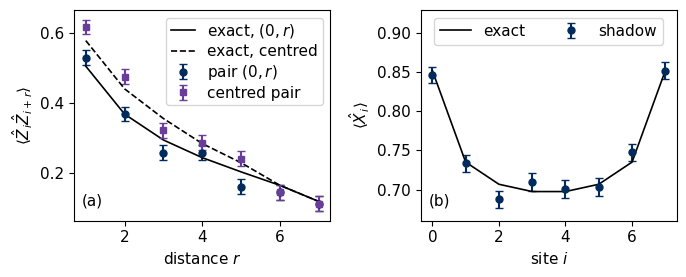

In [7]:
M_ONE = 20000
A1 = A_pool[:M_ONE]
e_m = -J * np.sum(A1[:, :-1, ZCODE] * A1[:, 1:, ZCODE], axis=1) - h * np.sum(A1[:, :, XCODE], axis=1)   # equation (10)
E_est, E_se = e_m.mean(), e_m.std(ddof=1) / np.sqrt(M_ONE)
e_wrong = (-J * np.sum(A1[:, :-1, ZCODE] * A1[:, 1:, ZCODE], axis=1) / 9 - h * np.sum(A1[:, :, XCODE], axis=1) / 3)
E_wrong, E_wrong_se = e_wrong.mean(), e_wrong.std(ddof=1) / np.sqrt(M_ONE)
x_val = A1[:, :, XCODE]                                                    # o_m(X_i), shape (M, N)
x_est, x_se = x_val.mean(0), x_val.std(0, ddof=1) / np.sqrt(M_ONE)
zz_val = A1[:, pair_i, ZCODE] * A1[:, pair_j, ZCODE]                       # o_m(Z_i Z_j) for all pairs
zz_est, zz_se = zz_val.mean(0), zz_val.std(0, ddof=1) / np.sqrt(M_ONE)
x_exact, zz_exact = exact1[:, XCODE], exact2[:, ZCODE, ZCODE]
dev = np.concatenate([(x_est - x_exact) / x_se, (zz_est - zz_exact) / zz_se])
mean_dev2 = float(np.mean(dev ** 2))
assert abs(E_est - E0) < 4 * E_se and abs(E_wrong - E0) > 10 * E_wrong_se
assert 0.5 < mean_dev2 < 1.6                                               # 36 correlated estimates
print(f"energy from {M_ONE} snapshots: {E_est:.4f} +- {E_se:.4f}, exact {E0:.4f}, deviation {(E_est - E0) / E_se:+.1f} standard errors")
print(f"control without the inverse channel: {E_wrong:.4f}, {(E_wrong - E0) / E_wrong_se:+.0f} standard errors from the exact value")
print(f"mean square of the normalised deviations of the 36 estimates: {mean_dev2:.2f}")
print(f"largest normalised deviation: {np.abs(dev).max():.2f} standard errors; {int(np.sum(np.abs(dev) < 2))} of {dev.size} estimates within two standard errors")
NUMBERS.update(MOne=f"{M_ONE:,}".replace(",", "\\,"), EEst=f"{E_est:.3f}", ESe=f"{E_se:.3f}", EWrong=f"{E_wrong:.2f}", MeanDevSq=f"{mean_dev2:.2f}")

r_dist = np.arange(1, N)
idx_0r = [PAIRS.index((0, r)) for r in r_dist]
idx_mid = [PAIRS.index((i, i + r)) if i + r < N else None for r in r_dist for i in [max(0, (N - 1 - r) // 2)]]
sites = np.arange(N)
def corr_panel(ax):
    ax.errorbar(r_dist, zz_est[idx_0r], yerr=zz_se[idx_0r], fmt="o", color=COL["navy"], ms=5, capsize=3, label=r"pair $(0,r)$")
    ax.plot(r_dist, zz_exact[idx_0r], "-", color=COL["exact"], lw=1.2, label="exact, $(0,r)$")
    ax.errorbar(r_dist, zz_est[idx_mid], yerr=zz_se[idx_mid], fmt="s", color=COL["purple"], ms=5, capsize=3, label="centred pair")
    ax.plot(r_dist, zz_exact[idx_mid], "--", color=COL["exact"], lw=1.2, label="exact, centred")
    ax.set_xlabel(r"distance $r$"); ax.set_ylabel(r"$\langle\hat Z_i\hat Z_{i+r}\rangle$"); ax.legend(loc="upper right", labelspacing=0.25, handlelength=1.6, borderpad=0.3)
def x_panel(ax):
    ax.errorbar(sites, x_est, yerr=x_se, fmt="o", color=COL["navy"], ms=5, capsize=3, label="shadow")
    ax.plot(sites, x_exact, "-", color=COL["exact"], lw=1.2, label="exact")
    ax.set_ylim(0.66, 0.93)
    ax.set_xlabel(r"site $i$"); ax.set_ylabel(r"$\langle\hat X_i\rangle$"); ax.legend(loc="upper center", ncol=2)
panels("fig_lab075_tfim", [corr_panel, x_panel], label_xy=[(0.03, 0.06, "bottom"), (0.03, 0.06, "bottom")])

The energy estimate agrees with the exact ground-state energy within two standard errors, and the standard error is below one percent of the energy, whereas the control without the inverse channel misses it by many standard errors. Panel (a) shows the correlation $\langle\hat Z_i\hat Z_{i+r}\rangle$ for the pairs $(0,r)$ that start at the edge of the chain (circles, exact values as the solid line) and for centred pairs (squares, exact values as the dashed line). The centred pair of distance $r$ is the pair $(i,i+r)$ with $i=\lfloor(N-1-r)/2\rfloor$, which lies as symmetrically about the middle of the chain as the distance allows. For $r=6$ and $r=7$ this gives $i=0$, so the two sets show the same pair there. The correlations decay with distance, and at equal distance they are smaller for the pairs that include the open end, where the spin has only one neighbour. Panel (b) shows the transverse magnetisation, which is enhanced at the open ends, where the field competes with only one $\hat Z\hat Z$ bond. The largest of the 36 normalised deviations is $2.0$ standard errors, and their mean square is close to one. About 5 % of Gaussian estimates deviate by more than two standard errors, so one or two such deviations among 36 estimates would also be compatible with correct error bars. The error bars are the same for all pairs, because every weight-two string has the variance $9-\langle\hat P\rangle^2$ of equation (7) regardless of the distance between its two qubits.

## 8. Convergence with the number of runs

By equation (7) the error of every estimate decreases as $M^{-1/2}$, with a prefactor set by the single-run variance. To measure this we split the pool into independent blocks of $M=100$ to $10\,000$ runs, estimate the energy in every block and compute the root-mean-square error over the blocks. The prediction is $\mathrm{std}(e_m)/\sqrt M$, with the single-run standard deviation of the energy taken from the whole pool.

single-run standard deviation of the energy: 9.06;  fitted slopes: energy -0.52, <Z_0 Z_4> -0.47
single-run variance of the energy 82.2; sum of the variances of its 15 terms 80.4 (bonds 8.69 each on average, fields 2.44);  single-run standard deviation of <Z_0 Z_4>: 3.00
blocks per M: {100: 1000, 200: 500, 500: 200, 1000: 100, 2000: 50, 5000: 20, 10000: 10}


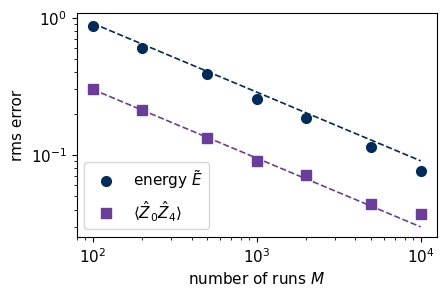

In [8]:
e_pool = -J * np.sum(A_pool[:, :-1, ZCODE] * A_pool[:, 1:, ZCODE], axis=1) - h * np.sum(A_pool[:, :, XCODE], axis=1)
zz_pool = A_pool[:, 0, ZCODE] * A_pool[:, 4, ZCODE]
zz04_exact = exact2[PAIRS.index((0, 4)), ZCODE, ZCODE]
M_GRID = np.array([100, 200, 500, 1000, 2000, 5000, 10000])
rms_E, rms_zz, n_blocks = [], [], []
for M in M_GRID:
    nb = M_POOL // M
    rms_E.append(np.sqrt(np.mean((e_pool[:nb * M].reshape(nb, M).mean(1) - E0) ** 2)))
    rms_zz.append(np.sqrt(np.mean((zz_pool[:nb * M].reshape(nb, M).mean(1) - zz04_exact) ** 2)))
    n_blocks.append(nb)
rms_E, rms_zz = np.array(rms_E), np.array(rms_zz)
slope_E = float(np.polyfit(np.log10(M_GRID), np.log10(rms_E), 1)[0])
slope_zz = float(np.polyfit(np.log10(M_GRID), np.log10(rms_zz), 1)[0])
sigma_e = e_pool.std(ddof=1)
assert -0.6 < slope_E < -0.4 and -0.6 < slope_zz < -0.4
print(f"single-run standard deviation of the energy: {sigma_e:.2f};  fitted slopes: energy {slope_E:.2f}, <Z_0 Z_4> {slope_zz:.2f}")
var_bonds = (A_pool[:, :-1, ZCODE] * A_pool[:, 1:, ZCODE]).var(axis=0, ddof=1)        # single-run variances of the 7 bond terms
var_fields = A_pool[:, :, XCODE].var(axis=0, ddof=1)                                 # and of the 8 field terms
print(f"single-run variance of the energy {sigma_e ** 2:.1f}; sum of the variances of its 15 terms {var_bonds.sum() + var_fields.sum():.1f} "
      f"(bonds {var_bonds.mean():.2f} each on average, fields {var_fields.mean():.2f});  single-run standard deviation of <Z_0 Z_4>: {zz_pool.std(ddof=1):.2f}")
print("blocks per M:", {int(m_): int(b_) for m_, b_ in zip(M_GRID, n_blocks)})
NUMBERS.update(SigmaE=f"{sigma_e:.1f}", SlopeE=f"{slope_E:.2f}", SlopeZZ=f"{slope_zz:.2f}")

def conv_panel(ax):
    ax.loglog(M_GRID, rms_E, "o", color=COL["navy"], ms=7, label=r"energy $\tilde E$")
    ax.loglog(M_GRID, sigma_e / np.sqrt(M_GRID), color=COL["navy"], lw=1.2, ls="--")
    ax.loglog(M_GRID, rms_zz, "s", color=COL["purple"], ms=7, label=r"$\langle\hat Z_0\hat Z_4\rangle$")
    ax.loglog(M_GRID, zz_pool.std(ddof=1) / np.sqrt(M_GRID), color=COL["purple"], lw=1.2, ls="--")
    ax.set_xlabel(r"number of runs $M$"); ax.set_ylabel("rms error"); ax.legend(loc="lower left")
single("fig_lab075_convergence", conv_panel)

Both errors follow the predicted lines $\mathrm{std}(o_m)/\sqrt M$ (dashed) with fitted slopes close to $-1/2$. The single-run standard deviation of the energy, $9.1$, is about three times that of a single correlation, $3.0$. Its square, about 82, is close to the sum of the single-run variances of the 15 terms of equation (10), about $8.7$ for each of the seven bonds and about $2.4$ for each of the eight field terms, 80 in total. The remainder comes from the correlations between terms of the same run. To halve the error one needs four times as many runs, as for every average of independent samples.

## 9. Dependence on the number of qubits

Equation (7) depends on the weight $k$ of the string alone. A local observable, such as the nearest-neighbour correlation $\langle\hat Z_0\hat Z_1\rangle$, is therefore estimated from $M$ runs with the same error for every chain length, whereas a string that acts on all qubits, such as the parity $\hat\Pi=\prod_i\hat X_i$, has an error that grows as $3^{N/2}$. The ground state is an eigenstate of $\hat\Pi$ with eigenvalue $+1$, so the parity estimate has variance $3^N-1$. We test both statements with $M=5000$ runs for the ground states of chains with $N=2,4,\dots,10$ qubits. For the parity, the measured standard error is reliable only while the expected number $M\,3^{-N}$ of matching runs is at least about ten.

N =  2: <Z0Z1> = +0.394 +- 0.041 (exact +0.447);  parity = +1.04 +- 0.04 (predicted error 0.04, 579 matching runs)
N =  4: <Z0Z1> = +0.475 +- 0.042 (exact +0.495);  parity = +1.23 +- 0.14 (predicted error 0.13, 76 matching runs)
N =  6: <Z0Z1> = +0.527 +- 0.042 (exact +0.503);  parity = +0.73 +- 0.33 (predicted error 0.38, 5 matching runs)
N =  8: <Z0Z1> = +0.472 +- 0.041 (exact +0.506);  parity: no run matched all bases, no estimate (predicted error 1.15, 0 matching runs)
N = 10: <Z0Z1> = +0.554 +- 0.042 (exact +0.507);  parity: no run matched all bases, no estimate (predicted error 3.44, 0 matching runs)


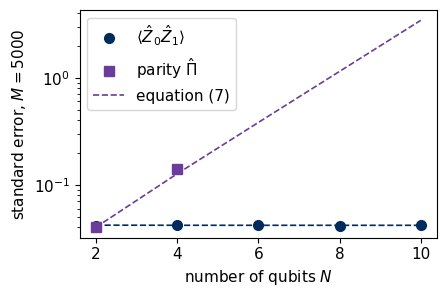

In [9]:
M_FIX = 5000
N_LIST = np.arange(2, 11, 2)
scan = []
for n in N_LIST:
    En, psin, _ = tfim_ground_state(int(n))
    key, k = jax.random.split(key)
    bn, on = collect(k, psin, M_FIX)
    v_zz = snapshot_values(bn, on, {0: ZCODE, 1: ZCODE})
    v_par = snapshot_values(bn, on, {q: XCODE for q in range(n)})
    zz_ex = exact_expectation(psin, {0: "Z", 1: "Z"})
    par_ex = exact_expectation(psin, {q: "X" for q in range(n)})
    assert abs(par_ex - 1) < 1e-8
    scan.append(dict(N=int(n), zz_est=float(v_zz.mean()), zz_se=float(v_zz.std(ddof=1) / np.sqrt(M_FIX)), zz_exact=zz_ex,
                     zz_pred=float(np.sqrt((9 - zz_ex ** 2) / M_FIX)), par_est=float(v_par.mean()),
                     par_se=float(v_par.std(ddof=1) / np.sqrt(M_FIX)), par_pred=float(np.sqrt((3.0 ** n - 1) / M_FIX)),
                     matches=int(np.sum(v_par != 0))))
for s in scan:
    parity_text = f"parity = {s['par_est']:+.2f} +- {s['par_se']:.2f}" if s["matches"] > 0 else "parity: no run matched all bases, no estimate"
    print(f"N = {s['N']:2d}: <Z0Z1> = {s['zz_est']:+.3f} +- {s['zz_se']:.3f} (exact {s['zz_exact']:+.3f});  "
          f"{parity_text} (predicted error {s['par_pred']:.2f}, {s['matches']} matching runs)")
zz_ses = np.array([s["zz_se"] for s in scan])
assert zz_ses.max() / zz_ses.min() < 1.1
for s in scan:
    assert abs(s["zz_est"] - s["zz_exact"]) < 4 * s["zz_se"]
    if M_FIX * 3.0 ** -s["N"] >= 10:
        assert abs(s["par_se"] / s["par_pred"] - 1) < 0.3
NUMBERS.update(MFix=f"{M_FIX}", ZZSeMin=f"{zz_ses.min():.3f}", ZZSeMax=f"{zz_ses.max():.3f}", ParPredTen=f"{scan[-1]['par_pred']:.1f}")

reliable = [s for s in scan if M_FIX * 3.0 ** -s["N"] >= 10]
def size_panel(ax):
    ax.semilogy(N_LIST, [s["zz_se"] for s in scan], "o", color=COL["navy"], ms=7, label=r"$\langle\hat Z_0\hat Z_1\rangle$")
    ax.semilogy(N_LIST, [s["zz_pred"] for s in scan], color=COL["navy"], lw=1.2, ls="--")
    ax.semilogy([s["N"] for s in reliable], [s["par_se"] for s in reliable], "s", color=COL["purple"], ms=7, label=r"parity $\hat\Pi$")
    ax.semilogy(N_LIST, [s["par_pred"] for s in scan], color=COL["purple"], lw=1.2, ls="--", label="equation (7)")
    ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(fr"standard error, $M={M_FIX}$")
    ax.legend(loc="upper left")
single("fig_lab075_size_scaling", size_panel)

The standard error of $\langle\hat Z_0\hat Z_1\rangle$ is the same for all chain lengths, from two to ten qubits, and agrees with equation (7). The error of the parity grows by $\sqrt3$ per qubit, and for $N\ge8$ no run of the 5000 matched all bases, so the parity cannot be estimated and only the prediction $\sqrt{(3^N-1)/M}$ of equation (7) is shown. The six-qubit point is omitted as well, since only about seven matching runs are expected there. The same exponential growth makes the fidelity with an entangled state such as the Greenberger–Horne–Zeilinger state hard to estimate from random single-qubit bases, since it involves strings of weight $N$. Random global Clifford circuits in place of single-qubit rotations make such fidelities cheap but require deep entangling circuits before every measurement [1]. For local observables the cost of shadows does not depend on the size of the system. The core route ends here. The last code cell of the notebook, after Section 10, prints the numbers and the runtime and runs directly from this point, and the exercises follow in Section 11.

## 10. Shadows and tomography at an equal number of runs

At home, we compare classical shadows with full tomography of the two-qubit Bell state $(|00\rangle+|11\rangle)/\sqrt2$ at the same total number of runs $M_{\mathrm{tot}}$. Tomography measures each of the nine settings $M_{\mathrm{tot}}/9$ times and estimates every Pauli string from the $3^{N-k}$ settings that measure it [9], while shadows draw a random setting for every run. From both data sets we estimate all 15 Pauli coefficients $r_P=\langle\hat P\rangle$ and the squared Hilbert–Schmidt distance $D_{\mathrm{HS}}^2=2^{-N}\sum_{P\neq I}(\tilde r_P-r_P)^2$ of the reconstructed state. In both schemes a string of weight $k$ is measured in a fraction $3^{-k}$ of the runs. Tomography fixes this fraction and obtains $\mathrm{Var}(\tilde r_P)=3^k(1-r_P^2)/M_{\mathrm{tot}}$, whereas the random number of matching runs in shadows gives $\mathrm{Var}(\tilde r_P)=(3^k-r_P^2)/M_{\mathrm{tot}}$ by equation (7). The two errors are equal for strings with $r_P=0$, and tomography is more precise for strings with $r_P=\pm1$, such as $\hat X\hat X$, $\hat Y\hat Y$ and $\hat Z\hat Z$ of the Bell state, whose fixed settings return the same parity in every run. We check both variances with 200 data sets for each budget.

M_tot =    90: mean D_HS^2  tomography 2.13e-01 (predicted 2.00e-01),  shadows 2.65e-01 (predicted 2.67e-01)
M_tot =   900: mean D_HS^2  tomography 1.93e-02 (predicted 2.00e-02),  shadows 2.73e-02 (predicted 2.67e-02)
M_tot =  9000: mean D_HS^2  tomography 2.01e-03 (predicted 2.00e-03),  shadows 2.64e-03 (predicted 2.67e-03)
ratio of the mean D_HS^2, shadows / tomography: 1.32 (predicted 1.33)


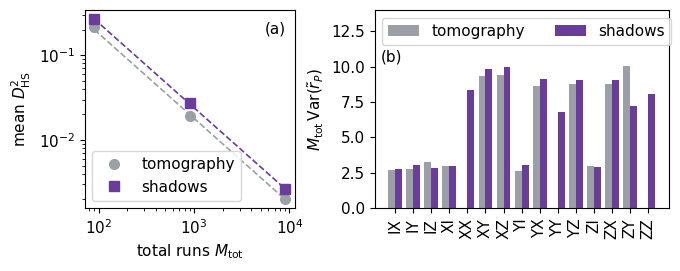

In [10]:
N2 = 2
psi_bell = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)
LAB2 = ["".join(p) for p in itertools.product("IXYZ", repeat=N2)]
r_exact = np.array([exact_expectation(psi_bell, {q: c for q, c in enumerate(lab) if c != "I"}) for lab in LAB2])
W2 = np.array([sum(c != "I" for c in lab) for lab in LAB2])
SET2 = ["".join(s) for s in itertools.product(BASES, repeat=N2)]
U2 = np.array([np.kron(ROT[BASES.index(a)], ROT[BASES.index(b)]) for a, b in SET2])
born2 = np.abs(np.einsum("sij,j->si", U2, psi_bell)) ** 2                   # p_s(b) for the nine settings

def parity_table(lab, s):
    # +-1 parity of the string lab for each outcome of setting s, or None if s does not measure lab
    if any(c != "I" and c != sc for c, sc in zip(lab, s)):
        return None
    return np.array([(-1) ** sum(((b >> (N2 - 1 - q)) & 1) for q, c in enumerate(lab) if c != "I") for b in range(4)])

@partial(jax.jit, static_argnums=(2, 3))
def tomo_outcomes(key, probs, shots, reps):
    # outcome indices of `shots` runs of each setting, for `reps` independent data sets: shape (reps, 9, shots)
    logits = jnp.log(jnp.clip(probs, 1e-300))
    return jax.random.categorical(key, logits[None, :, None, :], shape=(reps, probs.shape[0], shots))

LI2 = np.zeros((16, 9, 4))                     # linear map from frequencies to Pauli coefficients
for p, lab in enumerate(LAB2):
    compatible = [s for s in range(9) if parity_table(lab, SET2[s]) is not None]
    for s in compatible:
        LI2[p, s] = parity_table(lab, SET2[s]) / len(compatible)       # average over the 3^(N-k) settings
def tomo_estimate(counts):
    f = counts / counts.sum(axis=-1, keepdims=True)
    return np.einsum("...sb,psb->...p", f, LI2)

R_EB, budgets = 200, np.array([90, 900, 9000])
key, k1, k2 = jax.random.split(key, 3)
outcomes_t = np.asarray(tomo_outcomes(k1, jnp.asarray(born2), int(budgets.max() // 9), R_EB))   # one record, cut to each budget
b_all, o_all = collect(k2, psi_bell, int(R_EB * budgets.sum()), chunk=int(R_EB * budgets.min()))
res_eb, start = [], 0
for M_tot in budgets:
    counts_t = (outcomes_t[:, :, :M_tot // 9, None] == np.arange(4)).sum(axis=2)
    r_tomo = tomo_estimate(counts_t)
    b2, o2 = b_all[start:start + R_EB * M_tot], o_all[start:start + R_EB * M_tot]
    start += R_EB * M_tot
    A2 = factor_matrix(b2, o2).reshape(R_EB, int(M_tot), N2, 3)
    r_shad = np.ones((R_EB, 16))
    for p, lab in enumerate(LAB2[1:], start=1):
        v = np.ones((R_EB, int(M_tot)))
        for q, c in enumerate(lab):
            if c != "I":
                v = v * A2[:, :, q, BASES.index(c)]
        r_shad[:, p] = v.mean(axis=1)                                    # equation (6) averaged over the runs
    var_tomo_meas, var_shad_meas = r_tomo.var(axis=0, ddof=1) * M_tot, r_shad.var(axis=0, ddof=1) * M_tot
    var_tomo_pred, var_shad_pred = 3.0 ** W2 * (1 - r_exact ** 2), 3.0 ** W2 - r_exact ** 2
    d2_tomo = np.mean(np.sum((r_tomo - r_exact)[:, 1:] ** 2, axis=1) / 2 ** N2)
    d2_shad = np.mean(np.sum((r_shad - r_exact)[:, 1:] ** 2, axis=1) / 2 ** N2)
    res_eb.append(dict(M_tot=int(M_tot), d2_tomo=float(d2_tomo), d2_shad=float(d2_shad),
                       d2_tomo_pred=float(var_tomo_pred[1:].sum() / (2 ** N2 * M_tot)), d2_shad_pred=float(var_shad_pred[1:].sum() / (2 ** N2 * M_tot)),
                       var_tomo=var_tomo_meas.tolist(), var_shad=var_shad_meas.tolist()))
    print(f"M_tot = {M_tot:5d}: mean D_HS^2  tomography {d2_tomo:.2e} (predicted {res_eb[-1]['d2_tomo_pred']:.2e}),"
          f"  shadows {d2_shad:.2e} (predicted {res_eb[-1]['d2_shad_pred']:.2e})")
    assert abs(d2_tomo / res_eb[-1]["d2_tomo_pred"] - 1) < 0.15 and abs(d2_shad / res_eb[-1]["d2_shad_pred"] - 1) < 0.15
ratio_eb = res_eb[-1]["d2_shad_pred"] / res_eb[-1]["d2_tomo_pred"]
ratio_meas = float(np.mean([r["d2_shad"] / r["d2_tomo"] for r in res_eb]))
print(f"ratio of the mean D_HS^2, shadows / tomography: {ratio_meas:.2f} (predicted {ratio_eb:.2f})")
NUMBERS.update(EqualBudgetRatio=f"{ratio_eb:.2f}", EqualBudgetRatioMeasured=f"{ratio_meas:.2f}")

def budget_panel(ax):
    ax.loglog(budgets, [r["d2_tomo"] for r in res_eb], "o", color=COL["tomo"], ms=7, label="tomography")
    ax.loglog(budgets, [r["d2_tomo_pred"] for r in res_eb], color=COL["tomo"], lw=1.2, ls="--")
    ax.loglog(budgets, [r["d2_shad"] for r in res_eb], "s", color=COL["purple"], ms=7, label="shadows")
    ax.loglog(budgets, [r["d2_shad_pred"] for r in res_eb], color=COL["purple"], lw=1.2, ls="--")
    ax.set_xlabel(r"total runs $M_{\mathrm{tot}}$"); ax.set_ylabel(r"mean $D_{\mathrm{HS}}^2$"); ax.legend(loc="lower left")
def variance_panel(ax):
    xs = np.arange(1, 16); w_ = 0.38
    ax.bar(xs - w_ / 2, np.array(res_eb[-1]["var_tomo"])[1:], w_, color=COL["tomo"], label="tomography")
    ax.bar(xs + w_ / 2, np.array(res_eb[-1]["var_shad"])[1:], w_, color=COL["purple"], label="shadows")
    ax.set_xticks(xs); ax.set_xticklabels(LAB2[1:], rotation=90)
    ax.set_ylim(0, 14); ax.set_ylabel(r"$M_{\mathrm{tot}}\,\mathrm{Var}(\tilde r_P)$"); ax.legend(loc="upper left", ncol=2)
panels("fig_lab075_equal_budget", [budget_panel, variance_panel], label_xy=[(0.86, 0.94, "top"), (0.02, 0.80, "top")], width_ratios=[1, 1.4])

Panel (a) shows the mean squared Hilbert–Schmidt error of both reconstructions against the total number of runs, with the predictions as dashed lines. Both decrease as $1/M_{\mathrm{tot}}$, and for the Bell state the shadow error is larger by the predicted factor $96/72=4/3$, which the simulation reproduces. Panel (b) shows the variance of each Pauli coefficient multiplied by $M_{\mathrm{tot}}$ at the largest budget. The weight-one strings have the variance three and the weight-two strings nine in both schemes, except $\hat X\hat X$, $\hat Y\hat Y$ and $\hat Z\hat Z$, for which shadows give eight by equation (7) and tomography gives zero. The sums over the six weight-one and nine weight-two strings are therefore $18+78=96$ for shadows and $18+54=72$ for tomography. For two qubits shadows are thus a randomised form of tomography and offer no advantage. Their advantage appears for many qubits, where tomography needs all $3^N$ settings and a reconstruction of $4^N$ numbers, while shadows estimate local observables from any number of runs with an error that does not depend on $N$.

The last cell stores the numbers of this lab as LaTeX macros and a JSON summary and prints the runtime. When Section 10 has not been run, it prints the numbers of the core route and leaves the stored files unchanged.

## 11. Exercises

1. Derive the middle step of equation (1) by writing out the sum over $b=0,1$, and show that the channel with only the two bases $X$ and $Z$ cannot be inverted for every state.
2. Show that $\mathrm{Tr}\,\hat\rho_m^2=5^N$ for an $N$-qubit snapshot and use this to generalise equation (4).
3. Estimate $\langle\hat X_0\hat X_1\rangle$ and $\langle\hat Y_0\hat Z_1\rangle$ of the Ising ground state from the data set of Section 7. Explain why the second one vanishes, using that a string with an odd number of $\hat Y$ factors is an imaginary matrix and the ground state is real.
4. Estimate the connected correlation $\langle\hat Z_0\hat Z_r\rangle-\langle\hat Z_0\rangle\langle\hat Z_r\rangle$ from the same data set and find its error bar by splitting the runs into groups.
5. Repeat Section 6 for strings of weight four and compare the mean and the median of means when only a few runs per group match the string. The function `estimates` covers weights one and two only, so evaluate `snapshot_values` for a random subset of 200 of the 5670 strings of weight four.
6. Change the field to $h=0.5$ and $h=2$ and compare the correlations of Section 7 with those at the critical point.
7. Find, from equation (7), the number of runs needed to estimate the parity of a ten-qubit chain to an error of $0.1$, and compare it with the number of settings of full tomography.

## 12. Summary

Classical shadows measure every qubit in a random Pauli basis, one run at a time, and store the bases and the bits. Averaged over the random bases, the post-measurement state is the true state mixed with the identity, and inverting this measurement channel turns every record into a snapshot whose mean is the state. The expectation value of a Pauli string follows from each record as a product of single-qubit factors, three times the sign of the bit when the basis matches and zero otherwise, so the snapshot never has to be stored as a matrix. A string acting on $k$ qubits has the single-run variance $3^k-\langle\hat P\rangle^2$, which does not depend on the total number of qubits. One data set of $20\,000$ runs gives the energy and all 36 one- and two-point functions of the eight-qubit Ising ground state with error bars that agree with this variance, and the error decreases as $M^{-1/2}$. The median of means provides a bound that is logarithmic in the number of observables, whereas in our comparison on Pauli strings the plain mean was slightly more accurate. Local observables are estimated with the same error for every chain length, whereas strings that act on all qubits need a number of runs that grows as $3^N$. For two qubits shadows are a randomised form of tomography and offer no gain, and their advantage lies in local properties of many qubits.

## References

[1] H.-Y. Huang, R. Kueng and J. Preskill, Predicting many properties of a quantum system from very few measurements, Nat. Phys. **16**, 1050 (2020), doi:[10.1038/s41567-020-0932-7](https://doi.org/10.1038/s41567-020-0932-7).

[2] S. Aaronson, Shadow tomography of quantum states, in Proceedings of the 50th Annual ACM SIGACT Symposium on Theory of Computing (STOC 2018), p. 325, doi:[10.1145/3188745.3188802](https://doi.org/10.1145/3188745.3188802).

[3] A. Elben, S. T. Flammia, H.-Y. Huang, R. Kueng, J. Preskill, B. Vermersch and P. Zoller, The randomized measurement toolbox, Nat. Rev. Phys. **5**, 9 (2023), doi:[10.1038/s42254-022-00535-2](https://doi.org/10.1038/s42254-022-00535-2).

[4] P. Pfeuty, The one-dimensional Ising model with a transverse field, Ann. Phys. **57**, 79 (1970), doi:[10.1016/0003-4916(70)90270-8](https://doi.org/10.1016/0003-4916(70)90270-8).

[5] R. B. Lehoucq, D. C. Sorensen and C. Yang, ARPACK Users' Guide (SIAM, 1998), doi:[10.1137/1.9780898719628](https://doi.org/10.1137/1.9780898719628).

[6] J. Bradbury, R. Frostig, P. Hawkins, M. J. Johnson, C. Leary, D. Maclaurin, G. Necula, A. Paszke, J. VanderPlas, S. Wanderman-Milne and Q. Zhang, JAX: composable transformations of Python+NumPy programs (2018), [github.com/jax-ml/jax](https://github.com/jax-ml/jax).

[7] M. R. Jerrum, L. G. Valiant and V. V. Vazirani, Random generation of combinatorial structures from a uniform distribution, Theor. Comput. Sci. **43**, 169 (1986), doi:[10.1016/0304-3975(86)90174-X](https://doi.org/10.1016/0304-3975(86)90174-X).

[8] N. Alon, Y. Matias and M. Szegedy, The space complexity of approximating the frequency moments, J. Comput. Syst. Sci. **58**, 137 (1999), doi:[10.1006/jcss.1997.1545](https://doi.org/10.1006/jcss.1997.1545).

[9] D. F. V. James, P. G. Kwiat, W. J. Munro and A. G. White, Measurement of qubits, Phys. Rev. A **64**, 052312 (2001), doi:[10.1103/PhysRevA.64.052312](https://doi.org/10.1103/PhysRevA.64.052312).